# 04 · Which ranking to test

The ranking team proposed putting cheaper hotels first. This notebook compares four ways to
order a search's hotels — reviews first, cheapest first, and two rankings built from the choice
model — on **expected bookings per search** and **expected booking value**, using searches the
models never saw. The comparison follows the decision rule committed before this notebook was
written ([`reports/decision_rule.md`](../reports/decision_rule.md)).

**How a ranking is evaluated offline.** A booking model with an *outside option* ("clicked but
booked nothing") is fitted on 80% of the randomly ordered searches. For each held-out search,
each policy re-arranges the same hotels across the same slots; the model then gives the
probability that each hotel is booked and that nothing is. Because positions were random in
these searches, the model has seen what happens when good hotels land at the top by chance.

**What it cannot do.** Expedia's own ranking cannot be scored: the data does not say what
order Expedia would have shown in these searches.

In [1]:
import os
import sys
from pathlib import Path


def _project_root() -> Path:
    """The folder holding src/hotelrank, wherever the script or notebook was started."""
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "hotelrank" / "__init__.py").exists():
            return p
    for marker in here.glob("*/src/hotelrank/__init__.py"):
        return marker.parents[2]
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hotelrank import audit, choice, policy, position
from hotelrank.data import FIGURES_DIR, ROOT as PROJECT_ROOT, load
from hotelrank.records import write_metrics

N_BOOT = int(os.environ.get("HOTELRANK_N_BOOT", 200))
COLUMNS = ["srch_id", "position", "random_bool", "click_bool", "booking_bool", "price_usd", "prop_starrating",
           "prop_review_score", "prop_brand_bool", "prop_location_score1", "promotion_flag", "prop_id",
           "srch_length_of_stay", "srch_booking_window", "srch_adults_count", "srch_children_count",
           "srch_room_count", "srch_saturday_night_bool"]
df, SOURCE = load(COLUMNS)
flags_path = PROJECT_ROOT / "data" / "interim" / "search_flags.parquet"
if SOURCE == "real" and flags_path.exists():
    flags = pd.read_parquet(flags_path)
else:
    flags = audit.price_flags(df, audit.per_search(df)).reset_index().rename(columns={"index": "srch_id"})
x = position.analysis_sample(df, flags)
del df
x = policy.prepare(choice.add_hotel_mean_price(x[x["random_bool"].astype(bool)], full=x))
test = (x["srch_id"] % 5 == 0).to_numpy()  # the same split as notebook 03's hold-out
fit = policy.fit_booking_model(x[~test])
evalset = policy.make_eval_set(x[test])
print(SOURCE, f"train {fit.n_searches:,} searches, held out {evalset.n_searches:,}; converged={fit.converged}")

04-hotel-search-ranking\src\hotelrank\choice.py:131: RuntimeWarning: divide by zero encountered in log
  return float(np.log(p[d.chosen]).sum())


real train 91,516 searches, held out 23,165; converged=True


## 1. The booking model

Hotel attributes and position as in notebook 03; the outside option has a constant plus search
covariates (number of results, length of stay, booking window, party size, rooms, Saturday
night). Coefficients on the hotel side differ from notebook 03's booking model because this one
also learns from searches that ended without a booking.

In [2]:
coef = fit.table()
coef.loc[[c for c in policy.HOTEL_ATTRIBUTES + policy.OUTSIDE_COLUMNS if c in coef.index]].round(4)

,beta,se
log_price,-1.0786,0.0361
hotel_mean_log_price,0.5818,0.0425
prop_starrating,0.1621,0.0124
prop_review_score,0.2411,0.0175
no_reviews,0.0232,0.0901
prop_brand_bool,0.2773,0.0212
prop_location_score1,0.0308,0.0071
promotion_flag,0.3759,0.0226
outside,0.0145,0.1196
out_log_n_results,0.7272,0.0199


## 2. Is the evaluator trustworthy?

Two checks on the held-out searches, in the order actually shown:

1. **Calibration.** Predicted booking probability against the observed booking rate, by decile.
2. **Order luck.** The policies gain only if *the order* changes whether a booking happens. In
   each held-out search, compare the predicted probability under the shown order with its
   average over random re-shuffles of the same hotels: positive when good hotels happened to
   land on top. If the model is right, searches with more luck should book more than their
   shuffled average by about the predicted amount (slope 1); if order does not matter, slope 0.

In [3]:
calib = policy.evaluator_calibration(evalset, fit)
luck = policy.order_luck_check(evalset, fit)
overall = {"predicted_booking_rate": float(calib["pred"].mean()), "observed_booking_rate": float(evalset.booked_any.mean())}
print(overall, luck.attrs["slope"])
luck.round(4)

{'predicted_booking_rate': 0.1333115940852581, 'observed_booking_rate': 0.13179365421972805} {'slope': 0.35023052691821027, 'se': 0.323612381595005, 'ci': [-0.28404974100799946, 0.9845107948444201]}


,searches,predicted_uplift,observed_uplift,observed_se
bin,,,,
0,4633,-0.0073,0.0015,0.0053
1,4633,-0.0017,-0.0042,0.0044
2,4633,0.0007,0.0021,0.0044
3,4633,0.0034,-0.0048,0.0047
4,4633,0.0108,0.0036,0.0055


## 3. The four rankings

Expected bookings and booking value per held-out search, with 95% intervals from 200 replicates
that each draw the model's coefficients from their estimated uncertainty and re-weight the
held-out searches (search-level bootstrap). The logged random order is shown for reference.

In [4]:
result = policy.evaluate(evalset, fit, n_boot=N_BOOT, seed=11)
table = pd.DataFrame({
    k: {"bookings_per_search": b, "bookings_lo": policy.interval(result["draws"][k][:, 0])[0],
        "bookings_hi": policy.interval(result["draws"][k][:, 0])[1], "value_per_search_usd": v,
        "value_lo": policy.interval(result["draws"][k][:, 1])[0], "value_hi": policy.interval(result["draws"][k][:, 1])[1]}
    for k, (b, v) in result["point"].items()}).T
table.round(4)

,bookings_per_search,bookings_lo,bookings_hi,value_per_search_usd,value_lo,value_hi
B1_reviews_first,0.1384,0.1359,0.1406,46.7891,45.5734,48.1652
B2_cheapest_first,0.1369,0.1346,0.1393,35.4356,34.6231,36.4350
M1_most_likely_booked,0.1526,0.1502,0.1552,44.4149,43.1145,45.7617
M2_highest_expected_value,0.1423,0.1400,0.1448,50.4063,48.9994,51.9798
logged_random_order,0.1333,0.1313,0.1355,41.5721,40.5064,42.7881


## 4. The pre-declared decision

Applied mechanically: B\* and M\* are the baseline and the model ranking with the most expected
bookings. Test M\* only if its bookings beat B\*'s with the 95% interval of the difference above
zero **and** its booking value is no more than 2% lower.

In [5]:
decision = policy.apply_decision_rule(result)
decision

{'B_star': 'B1_reviews_first',
 'M_star': 'M1_most_likely_booked',
 'bookings_diff': 0.014187925571289756,
 'bookings_diff_ci': [0.013089040604941466, 0.01537323785544829],
 'bookings_rel_change': 0.10252861337361008,
 'value_rel_change': -0.050742383227667776,
 'condition_1_bookings': True,
 'condition_2_value': False,
 'recommend': 'B1_reviews_first',
 'failed': ['booking value more than 2% lower'],
 'cheapest_first_vs_reviews_first': {'bookings_diff': -0.0014638312726806546,
  'bookings_diff_ci': [-0.0027506076724748254, -1.2489951797152681e-05],
  'value_rel_change': -0.24265294399617776}}

## 5. Beyond the rule (exploratory)

The rule picks the model ranking by bookings alone. A family of rankings between M1 (most
likely to be booked) and M2 (highest expected value) shows the trade-off between the two
metrics; these are point estimates and were not part of the pre-declared comparison.

In [6]:
p_hat = policy.Params.from_vector(fit.names, fit.beta)
frontier = []
for lam in np.linspace(0, 1, 11):
    o = policy.outcomes(evalset, p_hat, policy.assign_slots(evalset, policy.blend_scores(evalset, p_hat, lam)))
    frontier.append({"lambda": round(float(lam), 2), "bookings": o["bookings"], "value": o["value"]})
frontier = pd.DataFrame(frontier)
b1 = result["point"]["B1_reviews_first"]
dominates_b1 = frontier[(frontier["bookings"] > b1[0]) & (frontier["value"] > b1[1])]
print(f"blends that beat reviews-first on both metrics: {len(dominates_b1)} of {len(frontier)}")
frontier.round(4)

blends that beat reviews-first on both metrics: 8 of 11


,lambda,bookings,value
0,0.0,0.1526,44.4149
1,0.1,0.1524,45.2572
2,0.2,0.1521,46.1509
3,0.3,0.1514,47.0433
4,0.4,0.1504,47.9028
5,0.5,0.1492,48.6667
6,0.6,0.1478,49.2912
7,0.7,0.1464,49.7631
8,0.8,0.1449,50.0888
9,0.9,0.1436,50.2962


## 6. Figure

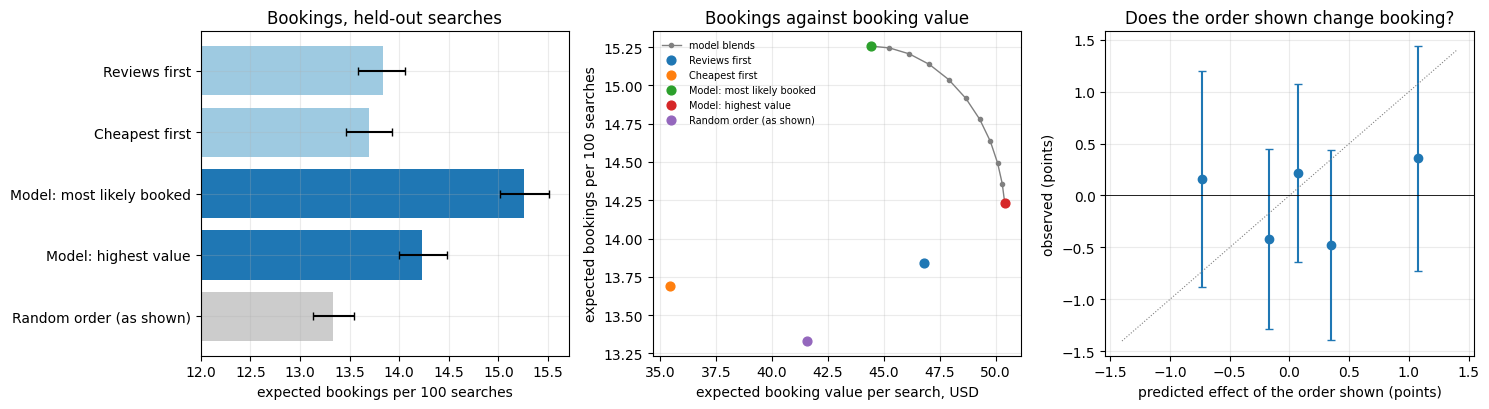

In [7]:
labels = {"B1_reviews_first": "Reviews first", "B2_cheapest_first": "Cheapest first",
          "M1_most_likely_booked": "Model: most likely booked", "M2_highest_expected_value": "Model: highest value",
          "logged_random_order": "Random order (as shown)"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
order = list(labels)
y = np.arange(len(order))
vals = [table.loc[k, "bookings_per_search"] * 100 for k in order]
err = np.clip([[(table.loc[k, "bookings_per_search"] - table.loc[k, "bookings_lo"]) * 100 for k in order],
               [(table.loc[k, "bookings_hi"] - table.loc[k, "bookings_per_search"]) * 100 for k in order]], 0, None)
axes[0].barh(y, vals, xerr=err, color=["#9ecae1", "#9ecae1", "#1f77b4", "#1f77b4", "#cccccc"], capsize=3)
axes[0].set_yticks(y, [labels[k] for k in order])
axes[0].invert_yaxis()
axes[0].set(xlabel="expected bookings per 100 searches", title="Bookings, held-out searches")
axes[0].set_xlim(min(vals) * 0.9, max(vals) * 1.03)
axes[1].plot(frontier["value"], frontier["bookings"] * 100, color="grey", lw=1, marker=".", label="model blends")
for k in order:
    b, v = result["point"][k]
    axes[1].scatter(v, b * 100, s=40, label=labels[k], zorder=3)
axes[1].set(xlabel="expected booking value per search, USD", ylabel="expected bookings per 100 searches",
            title="Bookings against booking value")
axes[1].legend(frameon=False, fontsize=7)
axes[2].errorbar(luck["predicted_uplift"] * 100, luck["observed_uplift"] * 100, yerr=1.96 * luck["observed_se"] * 100,
                 fmt="o", capsize=3)
lim = max(abs(luck["predicted_uplift"]).max(), abs(luck["observed_uplift"]).max()) * 100 * 1.3
axes[2].plot([-lim, lim], [-lim, lim], ls=":", color="grey", lw=0.8)
axes[2].axhline(0, color="black", lw=0.6)
axes[2].set(xlabel="predicted effect of the order shown (points)", ylabel="observed (points)",
            title="Does the order shown change booking?")
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()

In [8]:
def draws_ci(k, col):
    lo, hi = policy.interval(result["draws"][k][:, col])
    return [round(lo, 6), round(hi, 6)]


record = {
    "sample": {"train_searches": fit.n_searches, "heldout_searches": evalset.n_searches, "n_boot": N_BOOT},
    "booking_model": {"names": fit.names, "beta": [round(float(b), 6) for b in fit.beta],
                      "se": [round(float(s), 6) for s in fit.se], "converged": fit.converged,
                      "ridge": policy.RIDGE, "mcfadden_r2": round(fit.mcfadden_r2, 4)},
    "evaluator": {**{k: round(v, 5) for k, v in overall.items()},
                  "calibration": {int(i): {"pred": round(float(r.pred), 5), "obs": round(float(r.obs), 5)}
                                  for i, r in calib.iterrows()},
                  "order_luck": {int(i): {c: round(float(r[c]), 6) for c in luck.columns} for i, r in luck.iterrows()},
                  "order_luck_slope": {k: (round(v, 4) if not isinstance(v, list) else [round(z, 4) for z in v])
                                       for k, v in luck.attrs["slope"].items()}},
    "policies": {k: {"bookings_per_search": round(b, 6), "bookings_ci": draws_ci(k, 0),
                     "value_per_search_usd": round(v, 4), "value_ci": draws_ci(k, 1)}
                 for k, (b, v) in result["point"].items()},
    "decision": decision,
    "frontier_exploratory": frontier.round(6).to_dict(orient="records"),
}
out_path = write_metrics("04_policy_evaluation", record, SOURCE)
print("wrote", out_path.relative_to(PROJECT_ROOT) if SOURCE == "real" else out_path.name)
if SOURCE == "real":
    fig.savefig(FIGURES_DIR / "04_policy_evaluation.png", dpi=150, bbox_inches="tight")

wrote reports\metrics\04_policy_evaluation.json
